# Analyse des lignes de commande d'achat (`purchase_order_lines`) : exploration, patterns et anomalies

**Contexte.** Ce notebook applique à la table `purchase_order_lines.csv` (lignes de commandes d'achat d'un ERP : site acheteur, fournisseur, article, quantité, unité, prix unitaire, devise, dates, classe d'autorisation, centre de coût, statut) **la même démarche que le notebook des expéditions (`shipments`)**. L'objectif est de comprendre la structure des données, puis de repérer des **comportements inhabituels** : combinaisons rares mais cohérentes (*patterns*) et lignes statistiquement atypiques (*anomalies*).


---
## 0. Configuration

### 0.1 Imports et modules utilitaires

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "utils").is_dir()),
	Path.cwd(),
)
if str(project_root) not in sys.path:
	sys.path.insert(0, str(project_root))

from utils.clean_csv import clean_csv
from utils.variable_analysis import analyser_variables, tracer_histogrammes
from utils.correlation_matrices import tracer_matrices
from utils.pattern_detection import lire_csv, enrichir, detecter_patterns, profiler_groupe, masque_itemset
from utils.anomaly_detection import detecter_anomalies


**Rapport.** Mêmes modules `utils` que pour les expéditions : `clean_csv` (nettoyage), `variable_analysis` (histogrammes et statistiques), `correlation_matrices` (Spearman / V de Cramér), `pattern_detection` (itemsets fréquents) et `anomaly_detection` (IQR, clustering, ABOD). Le dossier racine du projet est ajouté automatiquement au `sys.path`.

---
## 1. Chargement et nettoyage

### 1.1 Lecture et nettoyage du fichier


In [2]:
# 1) Quantités écrites avec leur unité ("88 case", "1 service") : on garde le nombre
brut = pd.read_csv("../data/logistics/purchase_order_lines.csv")
brut["ordered_quantity"] = brut["ordered_quantity"].astype(str).str.extract(r"^\s*([\d.,]+)")[0]

# 2) Nettoyage générique. outlier_method=None : on NE transforme PAS les prix élevés en valeurs manquantes
po, rapport = clean_csv(brut, outlier_method=None)

Avant nettoyage : (651, 16)
Nombre de doublons sur ['purchase_order_number'] : 0
Après suppression des doublons : (650, 16)
Dates normalisées : {'order_date': 'datetime64[ns]', 'requested_delivery_date': 'datetime64[ns]'}
item_category : 23 -> 18 modalités distinctes

Forme finale : (650, 16)
Valeurs manquantes après traitement :
Aucune


In [3]:
# Vérification : que ferait le nettoyage avec son réglage par défaut (IQR global, facteur 3) ?
po_defaut, _ = clean_csv(brut, verbose=False)
perdus = po_defaut.loc[po_defaut.unit_price.isna(), "item_code"].value_counts()
print(f"Prix transformés en valeurs manquantes par défaut : {int(perdus.sum())} sur {len(po_defaut)}")
print(perdus.to_string())

Prix transformés en valeurs manquantes par défaut : 53 sur 650
item_code
ITM-RES-001    22
ITM-MEQ-001    20
ITM-GRA-001    11


### Rapport d'analyse — nettoyage

**Résultats**
- La table passe de **651 à 650 lignes** (16 colonnes) : 1 doublon exact est supprimé (la commande `PO-2022-00022` figurait deux fois).
- `item_category` passe de **23 à 18 modalités** : des variantes de casse (par exemple `MONITORING_EQUIPMENT`, `MEDICAL_CONSUMABLES`) étaient comptées comme des catégories distinctes.
- Les deux colonnes de dates sont converties en vraies dates (`datetime`), contrairement au notebook des expéditions où elles restaient du texte.
- Huit quantités écrites avec leur unité (`"88 case"`, `"24 pack"`...) sont récupérées grâce au prétraitement ; six prix à virgule décimale (`"2469,48"`) sont convertis par le nettoyage.
- Le contrôle final indique *« Aucune »* valeur manquante.



### 1.3 Aperçu des données

In [4]:
po.head(5)

,purchase_order_number,purchase_order_line,order_date,ordering_facility_code,supplier_partner_code,item_code,item_description,item_category,ordered_quantity,ordered_unit,unit_price,currency,requested_delivery_date,authorization_class,declared_cost_center,order_status
0,PO-2014-00001,1,2014-06-24,FCL-1007,BP-30078,ITM-MED-001,General clinical consumable case,medical_consumables,73,case,157.85,VLN,2014-07-08,restricted,Clinical Programmes,completed
1,PO-2015-00001,1,2015-01-22,FCL-1010,BP-30068,ITM-TRN-001,Regional refrigerated transport service,transport_service,1,service,3482.27,VLN,2015-02-01,ordinary,Clinical Services,completed
2,PO-2015-00002,1,2015-01-29,FCL-1030,BP-30066,ITM-COM-001,Secure communication service,communication_service,1,service,1292.19,KRN,2015-02-26,ordinary,General Operations,completed
3,PO-2015-00003,1,2015-02-10,FCL-1010,BP-30080,ITM-LAB-002,Sample preparation material pack,laboratory_material,3,pack,458.67,VLN,2015-03-02,expedited,Clinical Services,completed
4,PO-2015-00004,1,2015-02-12,FCL-1022,BP-30021,ITM-GRA-001,Programme grant transfer,grant,1,grant,26933.28,KRN,2015-02-21,ordinary,Facilities,completed


**Rapport.** Les 16 colonnes se regroupent en : **identification** (`purchase_order_number`, `purchase_order_line`), **dates** (`order_date`, `requested_delivery_date`), **acteurs et lieux** (`ordering_facility_code` = site acheteur, `supplier_partner_code`), **article** (`item_code`, `item_description`, `item_category`), **commande** (`ordered_quantity`, `ordered_unit`, `unit_price`, `currency`) et **contexte** (`authorization_class`, `declared_cost_center`, `order_status`). Les premières lignes montrent déjà que l'article détermine presque tout : un service est commandé en quantité 1 au prix d'un service (≈ 1 300 à 3 500), une subvention (`grant`) en quantité 1 pour 26 933 `KRN`, un consommable médical en `case` en grande quantité à 157,85. La colonne `purchase_order_line` vaut 1 sur les cinq lignes affichées .

---
## 2. Analyse univariée

### 2.1 Histogrammes et statistiques descriptives



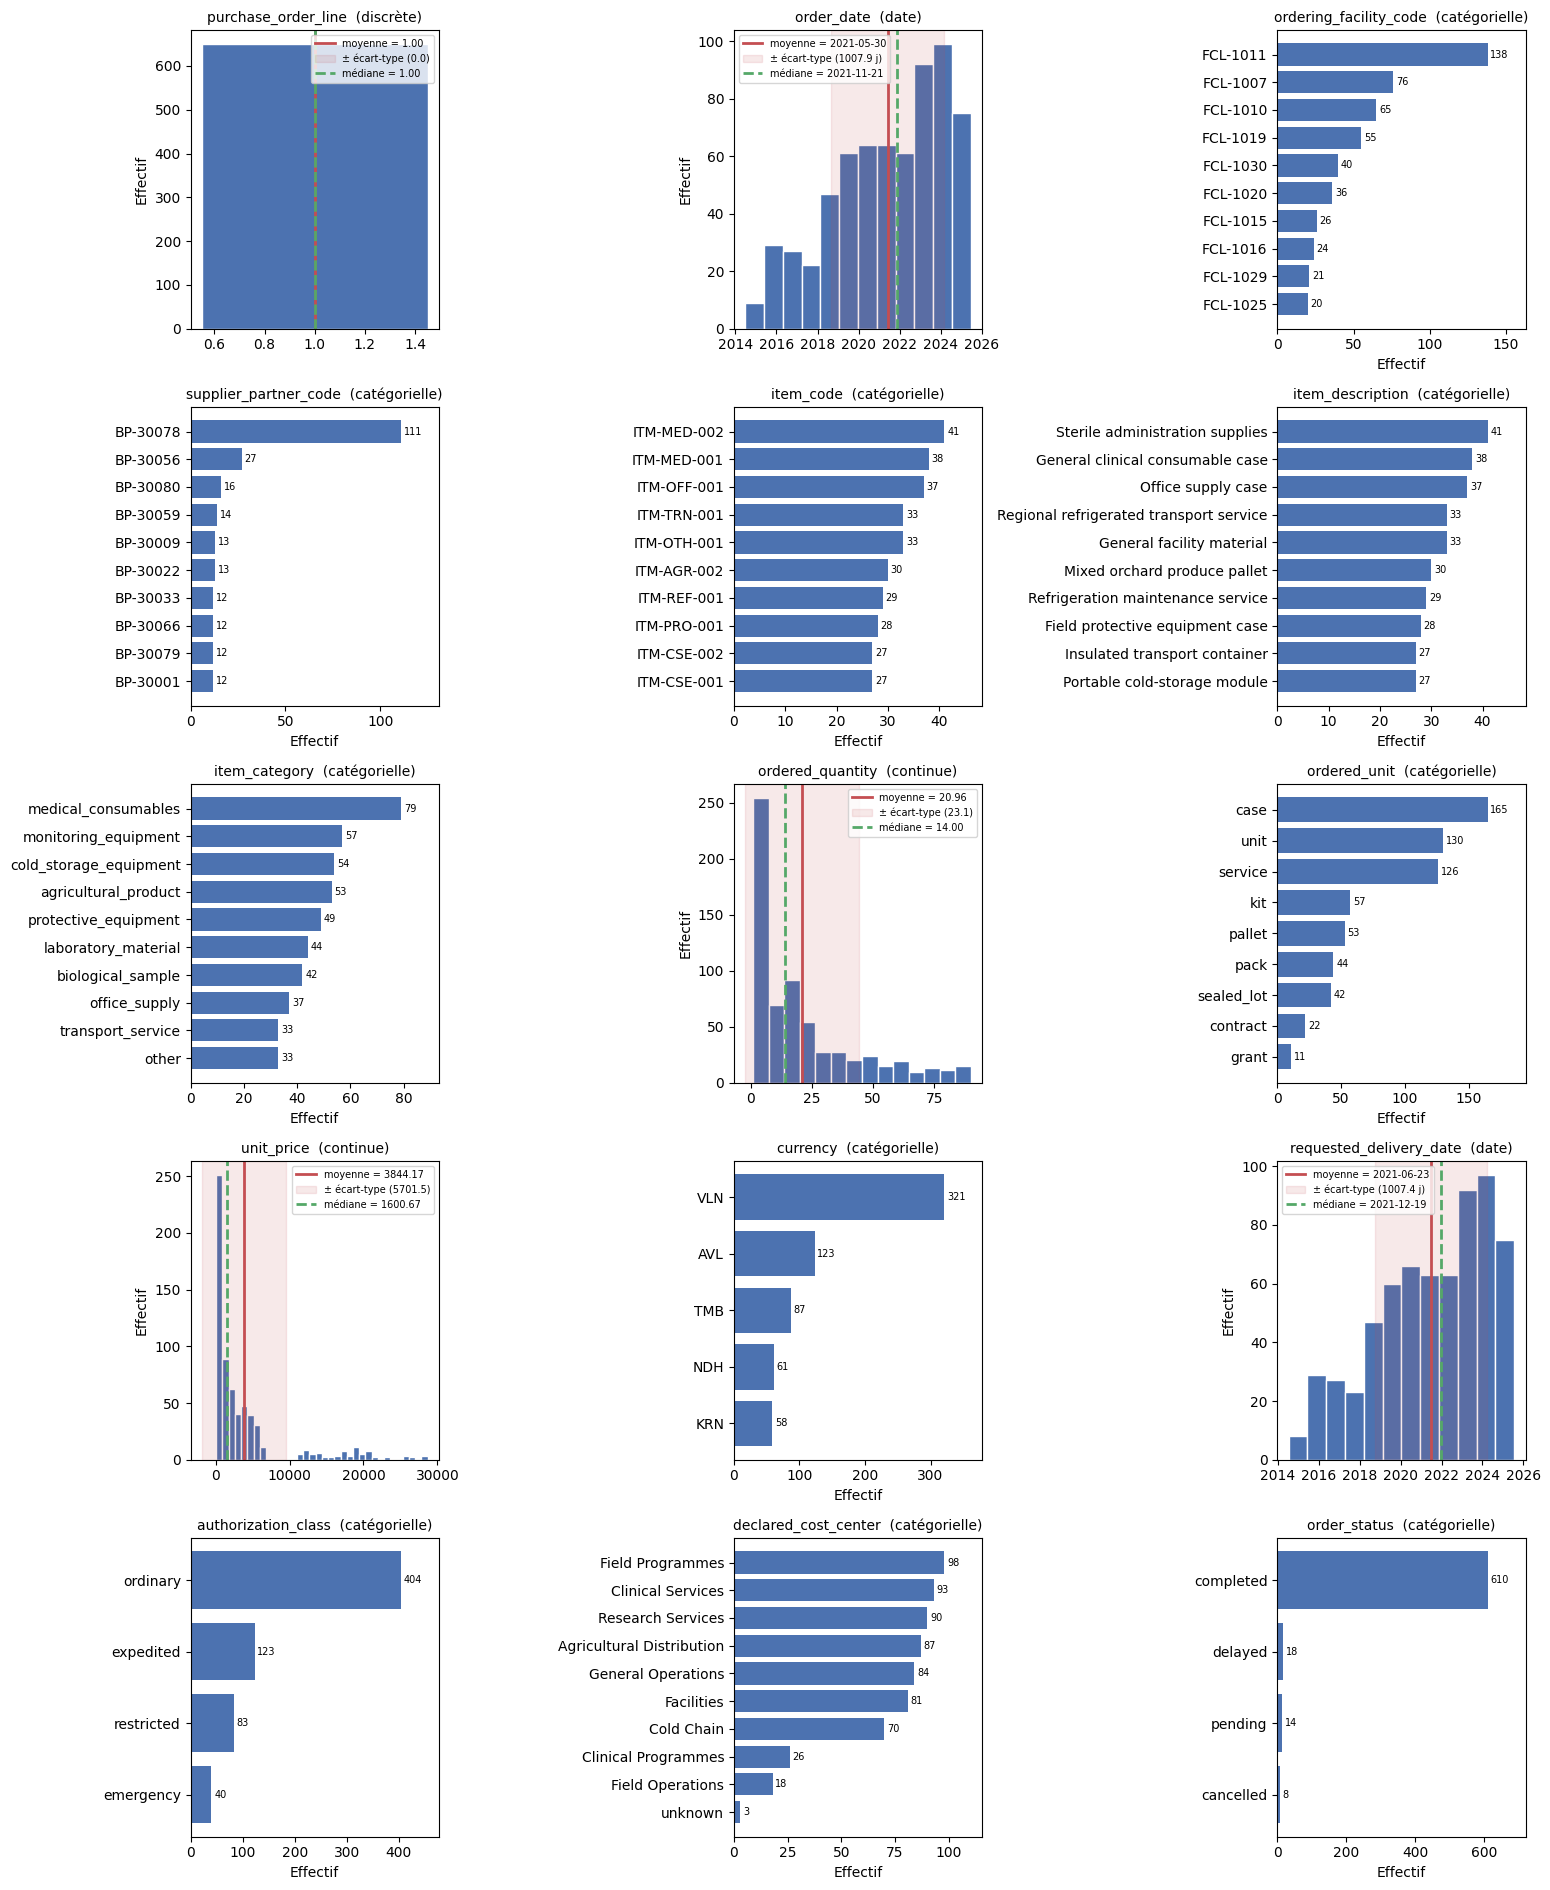


=== purchase_order_number  [identifiant] ===
  650 valeurs toutes (quasi) différentes : non analysée.

=== purchase_order_line  [discrète] ===
  Effectif : 650  (manquants : 0, valeurs distinctes : 1)
  Moyenne ± écart-type : 1.000 ± 0.000
  Médiane [min ; Q1 - Q3 ; max] : 1.000 [1.000 ; 1.000 - 1.000 ; 1.000]
  Asymétrie : 0.00


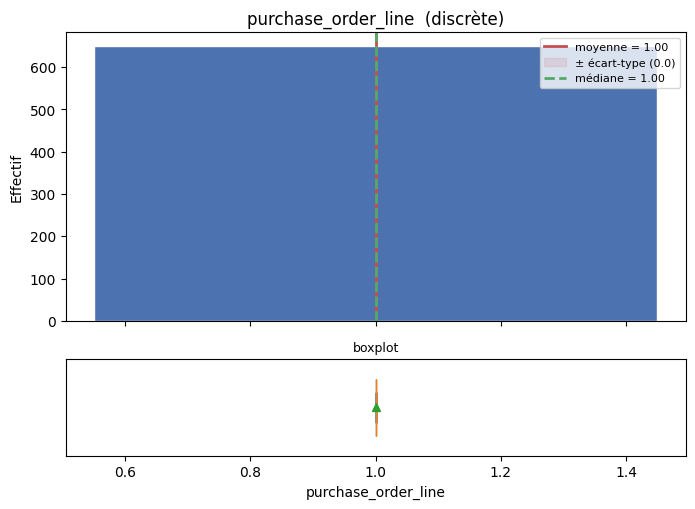


=== order_date  [date] ===
  Effectif : 650  (manquants : 0, valeurs distinctes : 449)
  Moyenne ± écart-type : 2021-05-30 ± 1007.9 jours
  Médiane [min ; Q1 - Q3 ; max] : 2021-11-21 [2014-06-24 ; 2019-09-06 - 2023-09-07 ; 2025-06-23]
  Asymétrie : -0.45


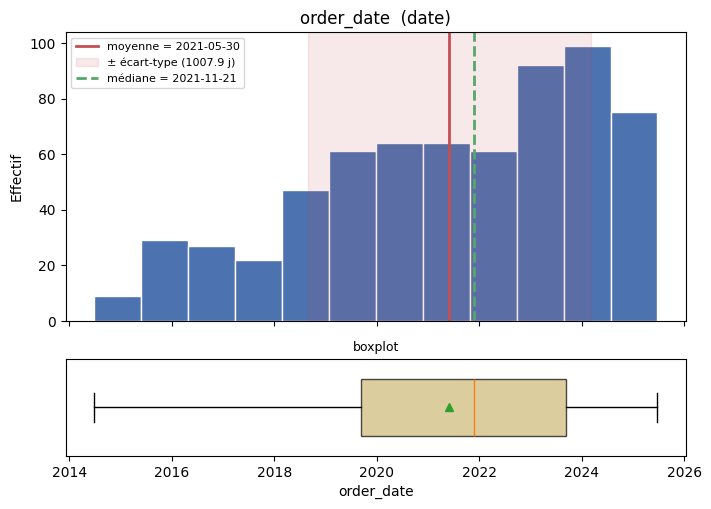


=== ordering_facility_code  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 30)
  Mode : FCL-1011 (21.2 %)
                        effectif     %
ordering_facility_code                
FCL-1011                     138  21.2
FCL-1007                      76  11.7
FCL-1010                      65  10.0
FCL-1019                      55   8.5
FCL-1030                      40   6.2
FCL-1020                      36   5.5
FCL-1015                      26   4.0
FCL-1016                      24   3.7
FCL-1029                      21   3.2
FCL-1025                      20   3.1
FCL-1014                      16   2.5
FCL-1009                      15   2.3
FCL-1002                      13   2.0
FCL-1003                      13   2.0
FCL-1023                      10   1.5


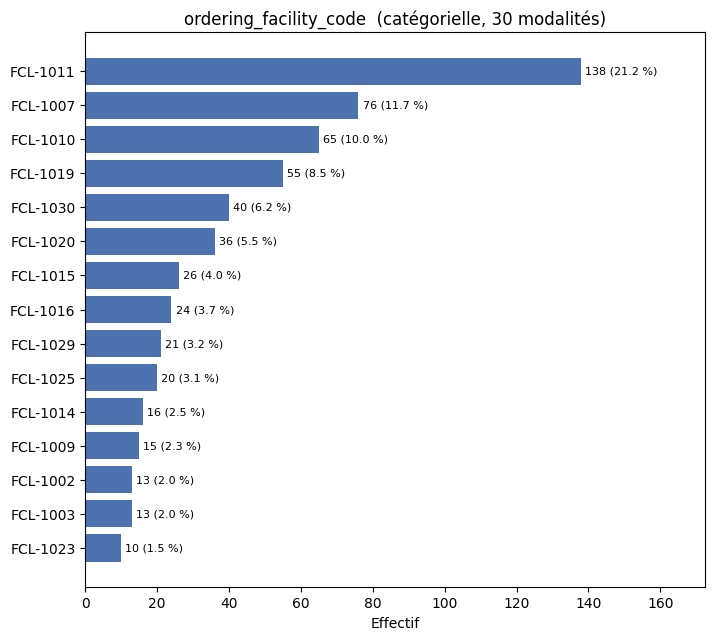


=== supplier_partner_code  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 69)
  Mode : BP-30078 (17.1 %)
                       effectif     %
supplier_partner_code                
BP-30078                    111  17.1
BP-30056                     27   4.2
BP-30080                     16   2.5
BP-30059                     14   2.2
BP-30009                     13   2.0
BP-30022                     13   2.0
BP-30033                     12   1.8
BP-30066                     12   1.8
BP-30079                     12   1.8
BP-30001                     12   1.8
BP-30028                     12   1.8
BP-30012                     11   1.7
BP-30021                     11   1.7
BP-30018                     11   1.7
BP-30053                     11   1.7


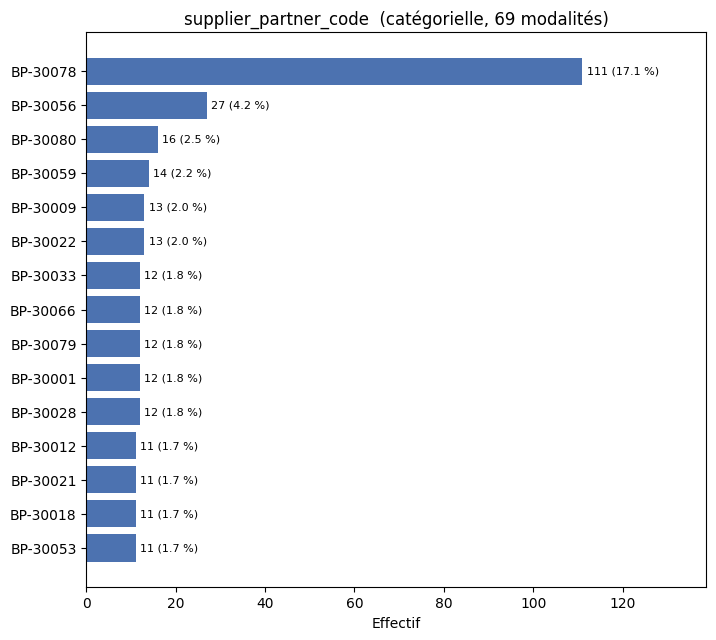


=== item_code  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 27)
  Mode : ITM-MED-002 (6.3 %)
             effectif    %
item_code                 
ITM-MED-002        41  6.3
ITM-MED-001        38  5.8
ITM-OFF-001        37  5.7
ITM-TRN-001        33  5.1
ITM-OTH-001        33  5.1
ITM-AGR-002        30  4.6
ITM-REF-001        29  4.5
ITM-PRO-001        28  4.3
ITM-CSE-002        27  4.2
ITM-CSE-001        27  4.2
ITM-CON-001        25  3.8
ITM-LAB-001        25  3.8
ITM-MON-002        24  3.7
ITM-AGE-001        23  3.5
ITM-AGR-001        23  3.5


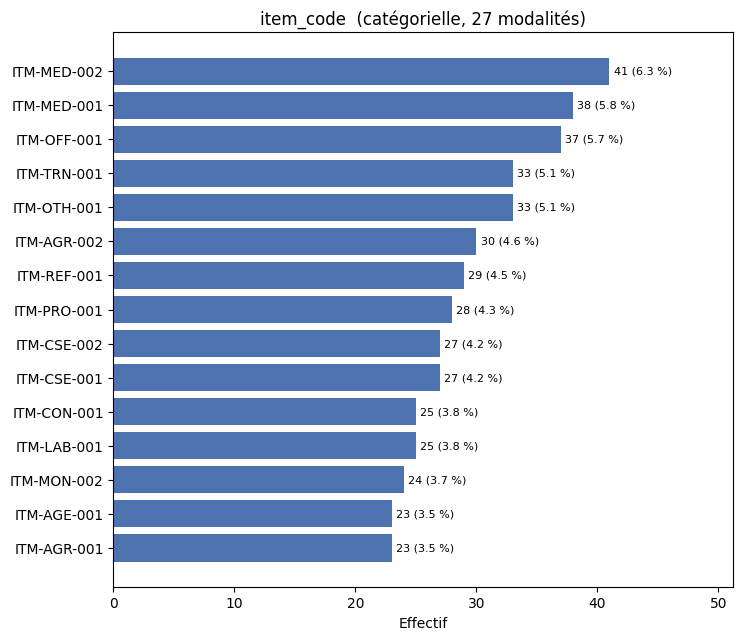


=== item_description  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 27)
  Mode : Sterile administration supplies (6.3 %)
                                         effectif    %
item_description                                      
Sterile administration supplies                41  6.3
General clinical consumable case               38  5.8
Office supply case                             37  5.7
Regional refrigerated transport service        33  5.1
General facility material                      33  5.1
Mixed orchard produce pallet                   30  4.6
Refrigeration maintenance service              29  4.5
Field protective equipment case                28  4.3
Insulated transport container                  27  4.2
Portable cold-storage module                   27  4.2
Operational consulting service                 25  3.8
Laboratory assay material pack                 25  3.8
Field camera and sensor kit                    24  3.7
Orchard maintenance equipment     

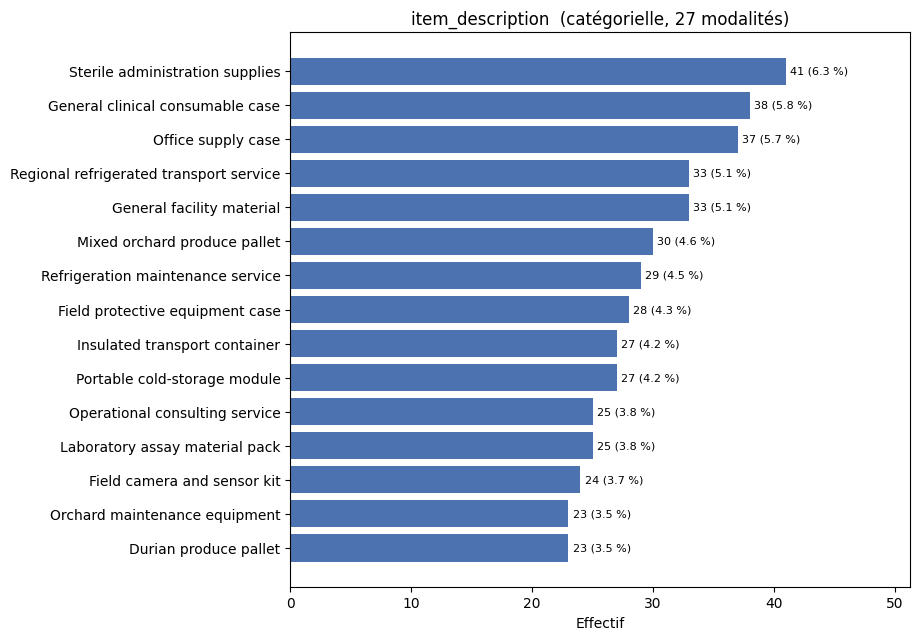


=== item_category  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 18)
  Mode : medical_consumables (12.2 %)
                        effectif     %
item_category                         
medical_consumables           79  12.2
monitoring_equipment          57   8.8
cold_storage_equipment        54   8.3
agricultural_product          53   8.2
protective_equipment          49   7.5
laboratory_material           44   6.8
biological_sample             42   6.5
office_supply                 37   5.7
transport_service             33   5.1
other                         33   5.1
refrigeration_service         29   4.5
consulting_service            25   3.8
agricultural_equipment        23   3.5
legal_service                 22   3.4
research_contract             22   3.4


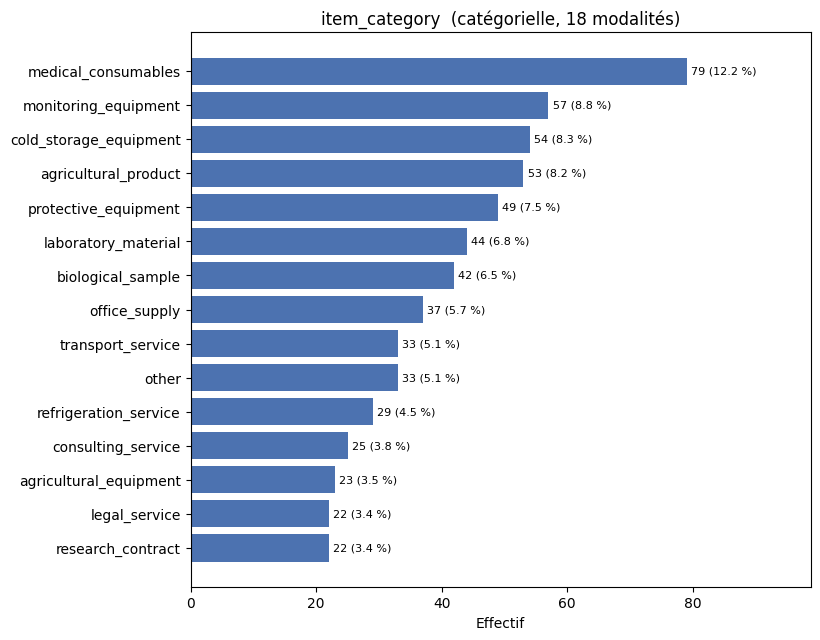


=== ordered_quantity  [continue] ===
  Effectif : 650  (manquants : 0, valeurs distinctes : 86)
  Moyenne ± écart-type : 20.965 ± 23.136
  Médiane [min ; Q1 - Q3 ; max] : 14.000 [1.000 ; 1.000 - 30.000 ; 90.000]
  Asymétrie : 1.30


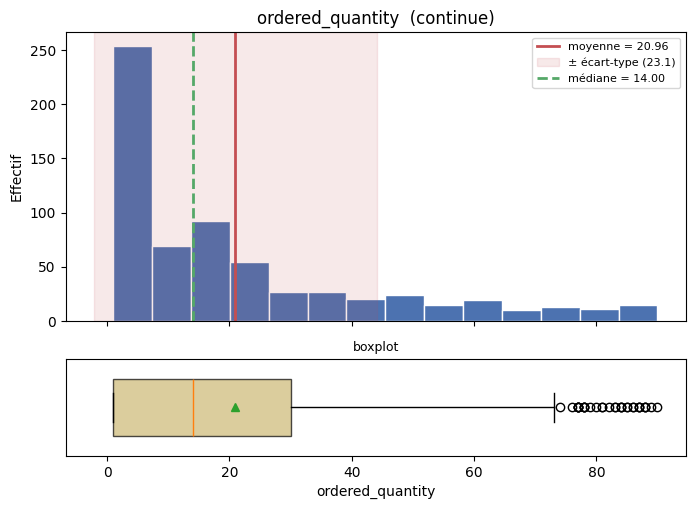


=== ordered_unit  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 9)
  Mode : case (25.4 %)
              effectif     %
ordered_unit                
case               165  25.4
unit               130  20.0
service            126  19.4
kit                 57   8.8
pallet              53   8.2
pack                44   6.8
sealed_lot          42   6.5
contract            22   3.4
grant               11   1.7


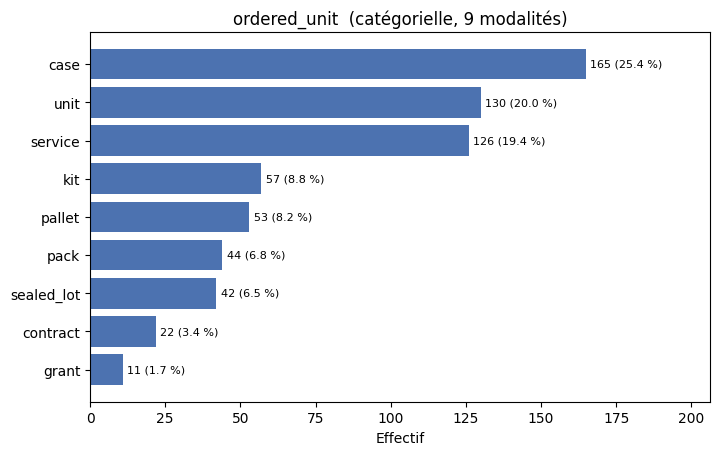


=== unit_price  [continue] ===
  Effectif : 650  (manquants : 0, valeurs distinctes : 650)
  Moyenne ± écart-type : 3844.169 ± 5701.539
  Médiane [min ; Q1 - Q3 ; max] : 1600.670 [83.810 ; 560.435 - 4243.115 ; 28663.740]
  Asymétrie : 2.30


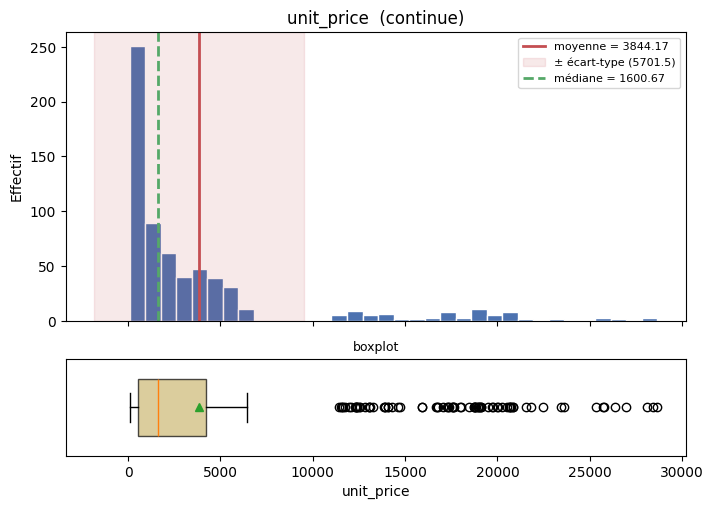


=== currency  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 5)
  Mode : VLN (49.4 %)
          effectif     %
currency                
VLN            321  49.4
AVL            123  18.9
TMB             87  13.4
NDH             61   9.4
KRN             58   8.9


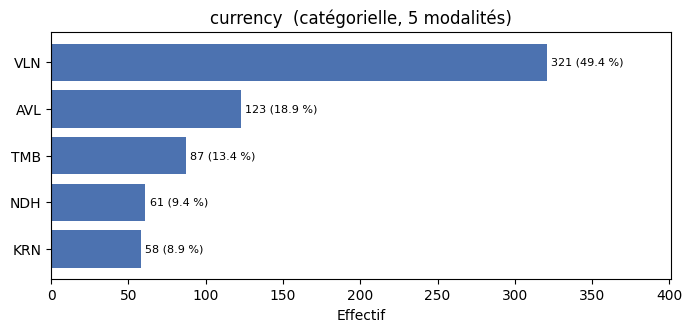


=== requested_delivery_date  [date] ===
  Effectif : 650  (manquants : 0, valeurs distinctes : 516)
  Moyenne ± écart-type : 2021-06-23 ± 1007.4 jours
  Médiane [min ; Q1 - Q3 ; max] : 2021-12-19 [2014-07-08 ; 2019-09-30 - 2023-09-27 ; 2025-07-22]
  Asymétrie : -0.45


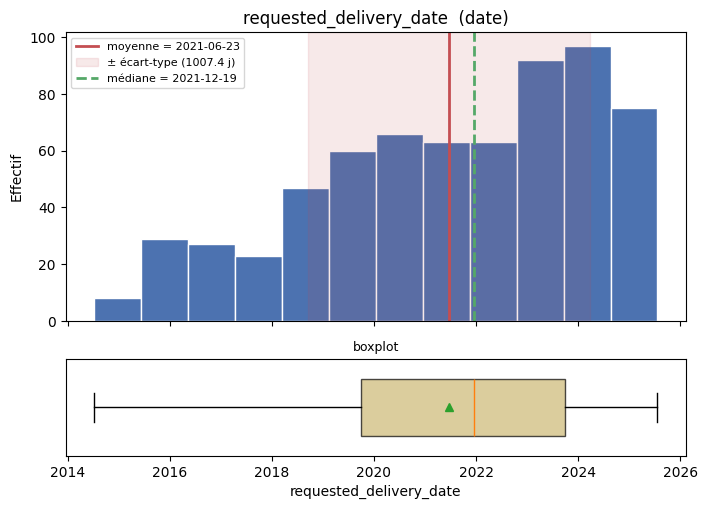


=== authorization_class  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 4)
  Mode : ordinary (62.2 %)
                     effectif     %
authorization_class                
ordinary                  404  62.2
expedited                 123  18.9
restricted                 83  12.8
emergency                  40   6.2


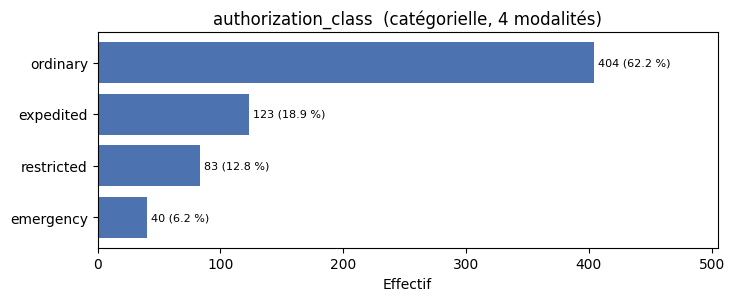


=== declared_cost_center  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 10)
  Mode : Field Programmes (15.1 %)
                           effectif     %
declared_cost_center                     
Field Programmes                 98  15.1
Clinical Services                93  14.3
Research Services                90  13.8
Agricultural Distribution        87  13.4
General Operations               84  12.9
Facilities                       81  12.5
Cold Chain                       70  10.8
Clinical Programmes              26   4.0
Field Operations                 18   2.8
unknown                           3   0.5


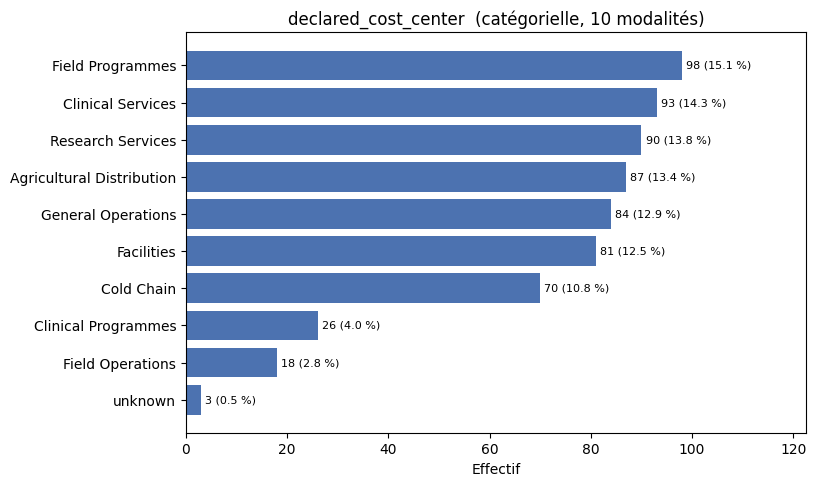


=== order_status  [catégorielle] ===
  Effectif : 650  (manquants : 0, modalités : 4)
  Mode : completed (93.8 %)
              effectif     %
order_status                
completed          610  93.8
delayed             18   2.8
pending             14   2.2
cancelled            8   1.2


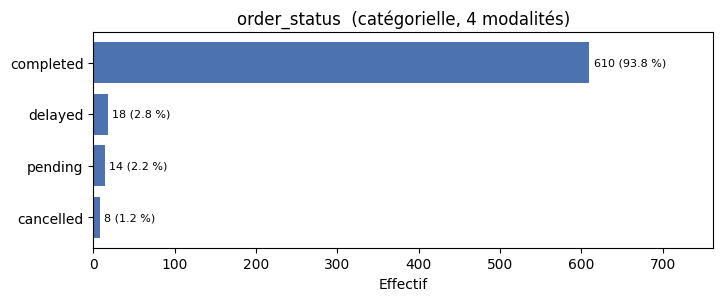

In [5]:
tracer_histogrammes(po)
resume = analyser_variables(po)

### Rapport d'analyse — analyse univariée

**1. Variables non exploitables ou particulières**
- `purchase_order_number` est un identifiant (650 valeurs distinctes) et `purchase_order_line` est **constante (= 1)** : chaque commande n'a qu'une ligne, comme `shipment_leg` dans les expéditions.
- Les deux dates sont analysées (elles ont été converties au nettoyage). `order_date` couvre du **24 juin 2014 au 23 juin 2025**, médiane au 21 novembre 2021, asymétrie −0,45 : l'activité augmente avec le temps (1 commande en 2014, 26 à 28 par an en 2015-2017, 53 à 71 en 2018-2021, **pic de 107 en 2023** ; calcul complémentaire). Le **délai de livraison demandé** va de 7 à 41 jours (médiane 24, Q1-Q3 de 16 à 32 ; calcul complémentaire).

**2. Acteurs et lieux : une forte concentration**
- 30 sites acheteurs : `FCL-1011` en passe **21,2 %** des lignes (138), puis `FCL-1007` 11,7 %, `FCL-1010` 10,0 % et `FCL-1019` 8,5 % ; ces quatre sites représentent plus de la moitié des commandes.
- 69 fournisseurs : `BP-30078` concentre **17,1 %** des lignes (111), puis `BP-30056` 4,2 % (27) ; tous les autres sont à 2,5 % ou moins. `BP-30078` est aussi le principal expéditeur dans la table des expéditions (20 %).

**3. Articles et unités**
- 27 articles (`item_code`) pour 18 catégories, sans article dominant (`ITM-MED-002` : 6,3 %). `medical_consumables` pèse 12,2 % (79 lignes), `monitoring_equipment` 8,8 % et `cold_storage_equipment` 8,3 %.
- 9 unités : `case` 25,4 %, `unit` 20,0 %, `service` 19,4 %, puis `kit`, `pallet`, `pack`, `sealed_lot` (6,5 à 8,8 %) et deux rares, `contract` (3,4 %) et `grant` (1,7 %).

**4. Quantité et prix : deux distributions très étalées à droite**
- Quantité : moyenne 21,0 ± 23,1, médiane **14**, Q1-Q3 de 1 à 30, maximum 90, asymétrie **1,30**. 171 lignes ont une quantité de 1 : services, contrats et subventions valent toujours 1 (calcul complémentaire).
- Prix unitaire : moyenne 3 844 ± 5 702, médiane **1 601**, de 83,81 à 28 663,74, asymétrie **2,30** (650 valeurs toutes distinctes). Le prix dépend de l'article : les prix médians atteignent 25 787 pour les subventions, 19 408 pour les équipements médicaux et 18 592 pour les contrats de recherche (calcul complémentaire).
- Devises : `VLN` 49,4 %, `AVL` 18,9 %, `TMB` 13,4 %, `NDH` 9,4 %, `KRN` 8,9 % ; elles ne sont pas convertibles en l'état.



---
## 3. Associations entre variables

### 3.1 Matrices de corrélation et V de Cramér



Colonnes constantes ou vides exclues : ['purchase_order_line']
Variables utilisées (4) : ['purchase_order_line (numérique)', 'order_date (date -> jours)', 'ordered_quantity (numérique)', 'unit_price (numérique)', 'requested_delivery_date (date -> jours)']
Variables exclues : ['purchase_order_number (identifiant)', 'ordering_facility_code (catégorielle)', 'supplier_partner_code (catégorielle)', 'item_code (catégorielle)', 'item_description (catégorielle)', 'item_category (catégorielle)', 'ordered_unit (catégorielle)', 'currency (catégorielle)', 'authorization_class (catégorielle)', 'declared_cost_center (catégorielle)', 'order_status (catégorielle)']


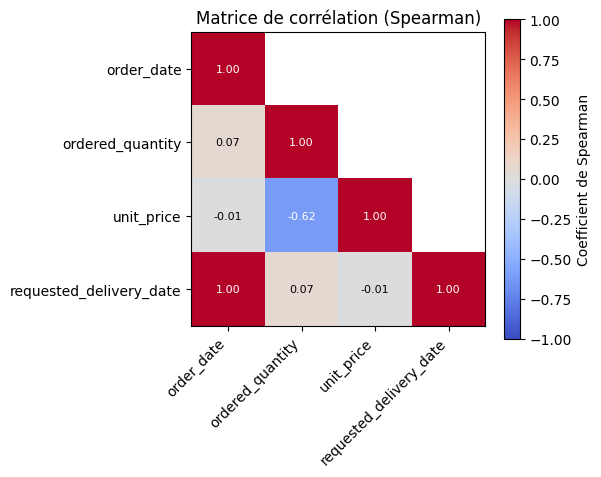


Paires avec |spearman| >= 0.7 :
             variable_1 variable_2   valeur
requested_delivery_date order_date 0.998969
Variables catégorielles utilisées (9) : ['ordering_facility_code', 'item_code', 'item_description', 'item_category', 'ordered_unit', 'currency', 'authorization_class', 'declared_cost_center', 'order_status']
Variables exclues : ['purchase_order_number (identifiant)', 'purchase_order_line (1 modalités)', 'order_date (date)', 'supplier_partner_code (69 modalités)', 'ordered_quantity (numérique)', 'unit_price (numérique)', 'requested_delivery_date (date)']


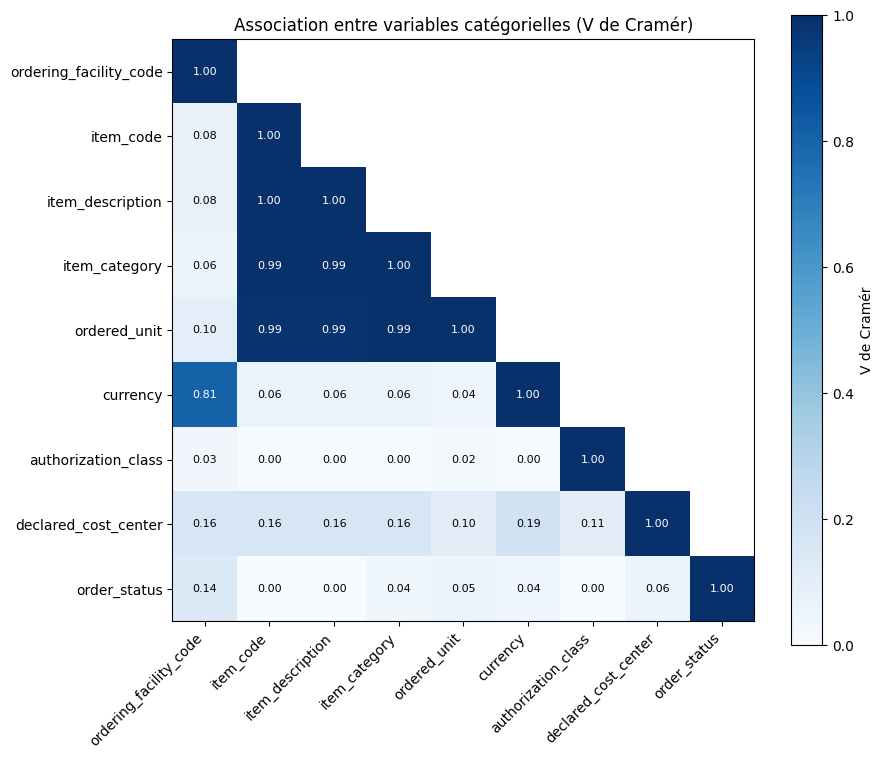


Paires avec |V de Cramér| >= 0.5 :
      variable_1             variable_2   valeur
item_description              item_code 1.000000
    ordered_unit          item_category 0.992955
   item_category              item_code 0.992854
   item_category       item_description 0.992854
    ordered_unit              item_code 0.985859
    ordered_unit       item_description 0.985859
        currency ordering_facility_code 0.808005


In [6]:
resultats = tracer_matrices(po)

### Rapport d'analyse — associations

**Interprétation**
- **Quatre variables portent la même information** : `item_code`, `item_description`, `item_category` et `ordered_unit` (V de 0,99 à 1,00). Il suffit de garder `item_code`. Les conserver toutes dans une recherche de patterns produit des résultats « évidents » (voir étape 4).
- **La corrélation négative quantité – prix (−0,62) est un effet de l'article, pas une loi économique** : les services, contrats et subventions se commandent à l'unité pour 18 000 à 28 000, alors que les consommables se commandent par dizaines de cartons à quelques centaines. À l'intérieur d'un même article, le prix reste presque constant (étape 5).
- **La devise dépend du site acheteur** (V = 0,81) : chaque site paie surtout dans la devise de sa région (par exemple, les 87 lignes en `TMB` viennent toutes de la région Tembara ; calcul complémentaire). La devise n'apporte donc pas d'information indépendante.
- **La classe d'autorisation et le statut sont presque indépendants du reste** : on ne peut pas prévoir une commande `emergency` ou `delayed` à partir de l'article, du site ou du prix.
- Le centre de coût est lui aussi faiblement lié à l'article (0,16) : les centres rares n'ont pas de logique de produit évidente à ce niveau.


---
## 4. Recherche de patterns : itemsets fréquents

### 4.1 Enrichissement et extraction des itemsets


Le tableau est d'abord enrichi avec : la région et les capacités de stockage du **site acheteur** (`erp_facilities`), et le rôle, le statut et la classe de risque du **fournisseur** (`erp_business_partners`). Les trois colonnes redondantes avec `item_code` (étape 3) sont exclues de la recherche.

In [7]:
fa = lire_csv("../data/logistics/erp_facilities.csv")
bp = lire_csv("../data/logistics/erp_business_partners.csv")

# Enrichissement : région / capacités du site acheteur, rôle / statut / risque du fournisseur
po_p = enrichir(po, fa, cle="ordering_facility_code", cle_autre="facility_code",
                colonnes=["region", "storage_capabilities"], prefixe="site_")
po_p = enrichir(po_p, bp, cle="supplier_partner_code", cle_autre="partner_code",
                colonnes=["partner_role", "partner_status", "risk_class"], prefixe="fourn_")

# item_description, item_category et ordered_unit sont redondants avec item_code (V de Cramér >= 0,99) :
# on les exclut pour éviter des itemsets "évidents" (même information répétée)
res = detecter_patterns(po_p, min_support=0.02,
                        exclure=["item_description", "item_category", "ordered_unit"])
F = res["itemsets"]

Transactions : 650 | colonnes utilisées : 15 | items distincts : 110
Colonnes exclues : ['purchase_order_number (identifiant)', 'purchase_order_line (constante)', 'supplier_partner_code (69 modalités > 30)']

min_support = 0.020 (support absolu >= 13) -> 50646 itemsets fréquents, dont 20175 fermés
Répartition par taille : {1: 90, 2: 1168, 3: 5352, 4: 11392, 5: 13849, 6: 10737, 7: 5588, 8: 1967, 9: 444, 10: 56, 11: 3}

--- Itemsets les plus FRÉQUENTS (taille >= 2) : décrivent surtout la majorité ---
                                                                                   itemset  support_abs  support_rel  lift
                                      fourn_partner_status=active ∧ order_status=completed          545        0.838 1.000
                                           order_date_weekend=non ∧ order_status=completed          439        0.675 1.006
                              order_status=completed ∧ requested_delivery_date_weekend=non          436        0.671 1.006
    

### 4.2 Profil du groupe le plus surprenant

*On décrit le groupe de lignes correspondant à l'itemset au lift le plus élevé (et non au plus fréquent, qui ne décrit que la majorité) : quelles variables y sont identiques à 95 % ou plus ?*

In [8]:
# Profil du groupe décrit par l'itemset le plus surprenant (et non le plus fréquent)
S = res["surprenants"]
itemset = frozenset(S.itemset.iloc[0])
groupe = masque_itemset(res["transactions"], itemset, po_p.index)
print("Itemset analysé :", " ∧ ".join(sorted(itemset)))
print("Effectif du groupe :", int(groupe.sum()), "lignes sur", len(po_p))
profil = profiler_groupe(po_p, groupe)
print(profil[profil.part_groupe >= 0.95][["colonne", "valeur_dominante", "part_groupe", "part_ensemble"]].to_string())

Itemset analysé : currency=vln ∧ declared_cost_center=clinical programmes ∧ fourn_partner_role=carrier ∧ fourn_partner_status=active ∧ fourn_risk_class=standard ∧ item_code=itm-med-001 ∧ order_date_weekend=non ∧ order_status=completed ∧ site_storage_capabilities=2-8c;controlled_access ∧ unit_price=[83.81 .. 687.5]
Effectif du groupe : 13 lignes sur 650
                      colonne                  valeur_dominante  part_groupe  part_ensemble
0        declared_cost_center               clinical programmes          1.0       0.040000
1                   item_code                       itm-med-001          1.0       0.058462
2            item_description  general clinical consumable case          1.0       0.058462
3               item_category               medical_consumables          1.0       0.121538
4       supplier_partner_code                          bp-30078          1.0       0.170769
5          fourn_partner_role                           carrier          1.0       0.247692
6

### Rapport d'analyse — patterns

**Résultats**
- Base : **650 transactions**, 15 colonnes, **110 items**. Exclues : `purchase_order_number`, `purchase_order_line` (constante) et `supplier_partner_code` (69 modalités > 30). Les dates sont transformées en indicateurs week-end/semaine, la quantité et le prix en tranches.
- À `min_support = 2 %` : **50 646 itemsets fréquents**, dont **20 175 fermés** (taille jusqu'à 11 items, avec un pic à 5). *Sans* l'exclusion des colonnes redondantes, on obtenait 104 934 itemsets (25 868 fermés) et des lifts supérieurs à **1 million**, purement tautologiques : une description, une catégorie et une unité qui répètent l'article ne sont pas une découverte.

**Itemsets les plus fréquents : le cas ordinaire**
- `fournisseur actif ∧ completed` (545 lignes, 83,8 %), `semaine ∧ completed` (439, 67,5 %), `ordinary ∧ completed` (377, 58,0 %)… Tous ont un **lift entre 0,99 et 1,02** : fréquents parce que leurs éléments le sont, sans lien particulier.

**Itemsets les plus surprenants (fermés, lift ≥ 3, support ≥ 10)**
1. **Centre de coût `Clinical Programmes`** : `ITM-MED-001` (consommable clinique en `case`), fournisseur de **rôle `carrier`** (transporteur) et de risque `standard`, devise `VLN`, sites de capacité `2-8c;controlled_access`, prix de 83,81 à 687,5 : **13 lignes** (2,0 %), lift ≈ 2 000. Une variante avec le site `FCL-1010` (région Valenne) en compte 14 (lift ≈ 1 000).
2. **Sites `FCL-1019` et `FCL-1030`** : le premier (région Eastern Avelora, devise `AVL`, capacités `ambient;secure_cage;2-8c;frozen`) revient avec des fournisseurs de rôle `carrier` sur 14 à 18 lignes ; le second (région Kintara, devise `KRN`, capacité `ambient`) sur 13 à 15 lignes. Lifts d'environ 450 à 540.

**Profil du groupe n° 1 (4.2)**
- Les 13 lignes sont **identiques à 100 %** sur : centre de coût `Clinical Programmes`, article `ITM-MED-001`, **un seul fournisseur : `BP-30078`**, de rôle `carrier`, risque `standard` et statut `active`, unité `case`, devise `VLN`, capacités `2-8c;controlled_access`, statut `completed`.

**Interprétation et réserves**
- Le second groupe est en grande partie **structurel** : un site détermine sa région, ses capacités et sa devise (V = 0,81 à l'étape 3). Ses lifts élevés ne signalent pas un comportement particulier.
- Le premier groupe, lui, est **informatif** : un centre de coût rare, un article précis, un seul fournisseur, et un fournisseur dont le rôle déclaré est « transporteur » et non « fournisseur ». Ce dernier point n'est pas isolé : seules **172 lignes sur 650 (26 %)** sont adressées à un partenaire de rôle `supplier` ou `supplier_customer`, et **161 (25 %)** à un partenaire `carrier` (calcul complémentaire) ; **69 lignes (10,6 %)** vont à des partenaires au statut `inactive`.
- Les lifts de plusieurs centaines à plusieurs milliers sont **gonflés mécaniquement** par la taille des itemsets (produit de nombreux petits supports) : ils indiquent une co-occurrence quasi systématique, pas une intensité mesurable.

### 4.3 Recoupement avec les expéditions

*Le groupe n° 1 pointe vers `Clinical Programmes`, l'un des deux centres de coût rares dont les effectifs (26 et 18) coïncident avec ceux des motifs « clinical » et « wildlife » des expéditions. On vérifie s'il s'agit d'un hasard : pour chaque ligne d'achat de ces centres de coût, on cherche, sur le même site, l'expédition correspondante postérieure à la commande, et on mesure le délai en jours.*

In [9]:
# Recoupement avec la table des expéditions (shipments) : à quoi correspondent les centres de coût rares ?
sh, _ = clean_csv("../data/logistics/shipments.csv", verbose=False)
sh["dispatch_day"] = pd.to_datetime(sh.dispatch_time, format="mixed").dt.normalize()

for centre, motif, cle_site in [("Clinical Programmes", "clinical", "destination_facility_code"),
                                ("Field Operations", "wildlife", "origin_facility_code")]:
    achats = po[po.declared_cost_center == centre]
    exped = sh[sh.declared_purpose.str.contains(motif)]
    ecarts = []
    for _, a in achats.iterrows():
        ex = exped[exped[cle_site] == a.ordering_facility_code]
        delta = (ex.dispatch_day - a.order_date).dt.days
        ecarts.append(delta[delta > 0].min() if (delta > 0).any() else np.nan)
    ecarts = pd.Series(ecarts)
    print(f"\n--- {centre} : {len(achats)} lignes d'achat | expéditions « {motif} » : {len(exped)} ---")
    print("Fournisseurs        :", achats.supplier_partner_code.value_counts().to_dict())
    print("Sites acheteurs     :", achats.ordering_facility_code.value_counts().to_dict())
    print("Catégories achetées :", achats.item_category.value_counts().to_dict())
    print("Délai achat -> expédition (même site), en jours :", ecarts.value_counts(dropna=False).to_dict())


--- Clinical Programmes : 26 lignes d'achat | expéditions « clinical » : 26 ---
Fournisseurs        : {'BP-30078': 26}
Sites acheteurs     : {'FCL-1010': 14, 'FCL-1007': 12}
Catégories achetées : {'medical_consumables': 19, 'biological_sample': 7}
Délai achat -> expédition (même site), en jours : {16: 26}

--- Field Operations : 18 lignes d'achat | expéditions « wildlife » : 18 ---
Fournisseurs        : {'BP-30078': 18}
Sites acheteurs     : {'FCL-1030': 7, 'FCL-1019': 7, 'FCL-1020': 4}
Catégories achetées : {'protective_equipment': 7, 'cold_storage_equipment': 6, 'monitoring_equipment': 5}
Délai achat -> expédition (même site), en jours : {19: 18}


### Rapport d'analyse — recoupement achats ↔ expéditions

**Résultats**
- **`Clinical Programmes` (26 lignes d'achat)** : toutes proviennent de **`BP-30078`**, passées par `FCL-1010` (14) et `FCL-1007` (12), pour 19 `medical_consumables` et 7 `biological_sample`. Chacune est suivie, **exactement 16 jours après la commande** (26 cas sur 26), d'une expédition « temperature-controlled clinical programme delivery » vers **le même site**.
- **`Field Operations` (18 lignes d'achat)** : toutes proviennent aussi de **`BP-30078`**, passées par `FCL-1030` (7), `FCL-1019` (7) et `FCL-1020` (4), pour du matériel : 7 `protective_equipment`, 6 `cold_storage_equipment` et 5 `monitoring_equipment`. Chacune est suivie, **exactement 19 jours après la commande** (18 cas sur 18), d'une expédition « environmental and wildlife reference materials » **partant du même site**.

**Interprétation**
- Les deux centres de coût rares ne sont pas des anomalies isolées : ils correspondent **un à un** aux deux flux spécialisés identifiés dans les expéditions (transporteur `BP-30047`, chaîne du froid), soit **44 lignes d'achat**, toutes chez un même fournisseur, `BP-30078`, qui est aussi le principal expéditeur de la table des expéditions (notamment depuis le site `FCL-1011`).
- Le **délai constant** (16 jours, puis 19 jours) est remarquable : le délai de livraison demandé sur ces commandes varie, lui, de 7 à 39 jours. Une telle régularité indique un **processus planifié** (commande qui déclenche une expédition), pas des événements indépendants.
- **Deux éléments méritent une vérification métier** : (1) le fournisseur est un partenaire de rôle `carrier` ; (2) pour `Field Operations`, les biens **achetés** (équipements de protection, de stockage au froid, de suivi) ne sont pas ceux qui sont **expédiés** (échantillons biologiques déclarés comme matériel de référence environnemental).



---
## 5. Détection d'anomalies


On utilise trois variables numériques : `unit_price`, `ordered_quantity` et le **délai demandé** `lead_time_days` (dates de livraison demandée − commande), variable dérivée plus parlante que deux dates brutes.

### 5.1 Détection globale (toutes les lignes comparées entre elles)

Variables utilisées (3) : ['unit_price', 'ordered_quantity', 'lead_time_days']

=== 1. Détection univariée (IQR) ===


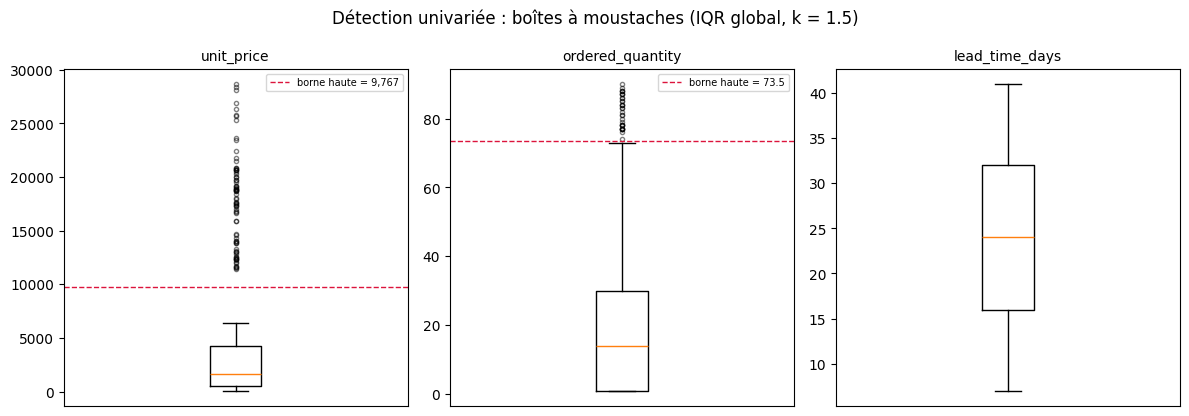

                    Q1    Q3   IQR  borne basse  borne haute  atypiques (IQR global)
variable                                                                            
unit_price       560.4 4,243 3,683       -4,964        9,767                      80
ordered_quantity     1    30    29        -42.5         73.5                      33
lead_time_days      16    32    16           -8           56                       0

=== 2. Détection multivariée par regroupement ===


c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038, 

K-means : k = 2 (silhouette 0.45), seuil de distance = 2.75 -> 17 atypiques
DBSCAN  : eps = 0.58, min_samples = 5 -> 3 groupes, 6 points bruit

=== 3. Angle-based Outlier Detection (ABOD) ===
ABOD    : FastABOD (k = 20), 3% d'ABOF les plus bas (seuil = 1.637) -> 20 atypiques


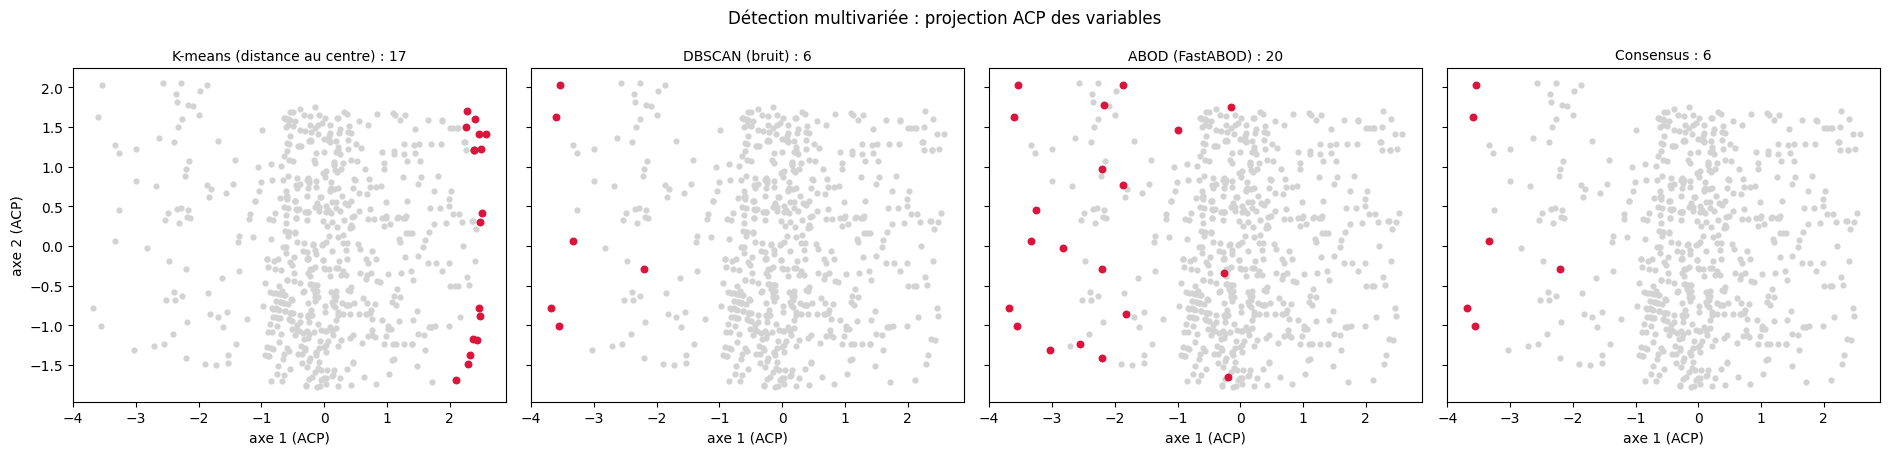


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 17, 'out_dbscan': 6, 'out_abod': 20}
Nombre de méthodes d'accord : {0: 613, 1: 31, 2: 6}
Lignes en consensus (>= 2 méthodes) : 6
Lignes avec au moins une valeur hors IQR : 113


In [10]:
# Délai demandé de livraison (jours) : variable dérivée des deux dates
po["lead_time_days"] = (po["requested_delivery_date"] - po["order_date"]).dt.days

# A) Détection globale : toutes les lignes sont comparées entre elles
resultat_global = detecter_anomalies(
    df=po, colonnes=["unit_price", "ordered_quantity", "lead_time_days"],
    show=True, contamination=0.03, min_methodes=2)

In [11]:
cols = ["purchase_order_number", "item_code", "ordered_quantity", "ordered_unit", "unit_price",
        "lead_time_days", "authorization_class", "order_status", "n_methodes"]
resultat_global.anomalies[cols].reset_index(drop=True)

,purchase_order_number,item_code,ordered_quantity,ordered_unit,unit_price,lead_time_days,authorization_class,order_status,n_methodes
0,PO-2015-00004,ITM-GRA-001,1,grant,26933.28,9,ordinary,completed,2
1,PO-2017-00021,ITM-MEQ-001,23,unit,21820.52,17,ordinary,completed,2
2,PO-2020-00018,ITM-GRA-001,1,grant,28663.74,35,ordinary,completed,2
3,PO-2020-00024,ITM-GRA-001,1,grant,28081.79,11,ordinary,completed,2
4,PO-2020-00034,ITM-GRA-001,1,grant,25726.91,20,ordinary,completed,2
5,PO-2024-00037,ITM-GRA-001,1,grant,28425.99,39,ordinary,completed,2


### 5.2 Détection par article (chaque ligne comparée à celles du même `item_code`)

*Dans `anomaly_detection`, l'option `group_by` calcule l'IQR **à l'intérieur de chaque groupe** et exprime les variables du multivarié par rapport à la médiane de leur groupe (log du ratio). Comme prévu aux étapes 1 et 3, c'est la bonne échelle de comparaison.*

Variables utilisées (3) : ['unit_price', 'ordered_quantity', 'lead_time_days']

=== 1. Détection univariée (IQR) ===


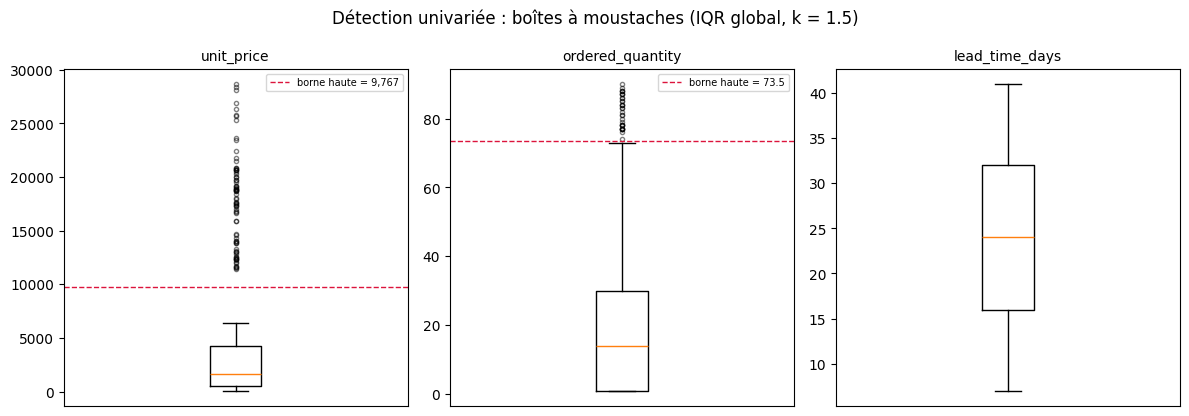

                    Q1    Q3   IQR  borne basse  borne haute  atypiques (IQR global)  atypiques (IQR par groupe)
variable                                                                                                        
unit_price       560.4 4,243 3,683       -4,964        9,767                      80                           0
ordered_quantity     1    30    29        -42.5         73.5                      33                           1
lead_time_days      16    32    16           -8           56                       0                           1
Variables exprimées relativement à la médiane de leur groupe (log du ratio si > 0).

=== 2. Détection multivariée par regroupement ===
K-means : k = 4 (silhouette 0.32), seuil de distance = 2.05 -> 11 atypiques
   (silhouette faible : peu de groupes nets ; les scores de distance restent exploitables)
DBSCAN  : eps = 0.87, min_samples = 5 -> 2 groupes, 6 points bruit

=== 3. Angle-based Outlier Detection (ABOD) ===
ABOD    : FastABO

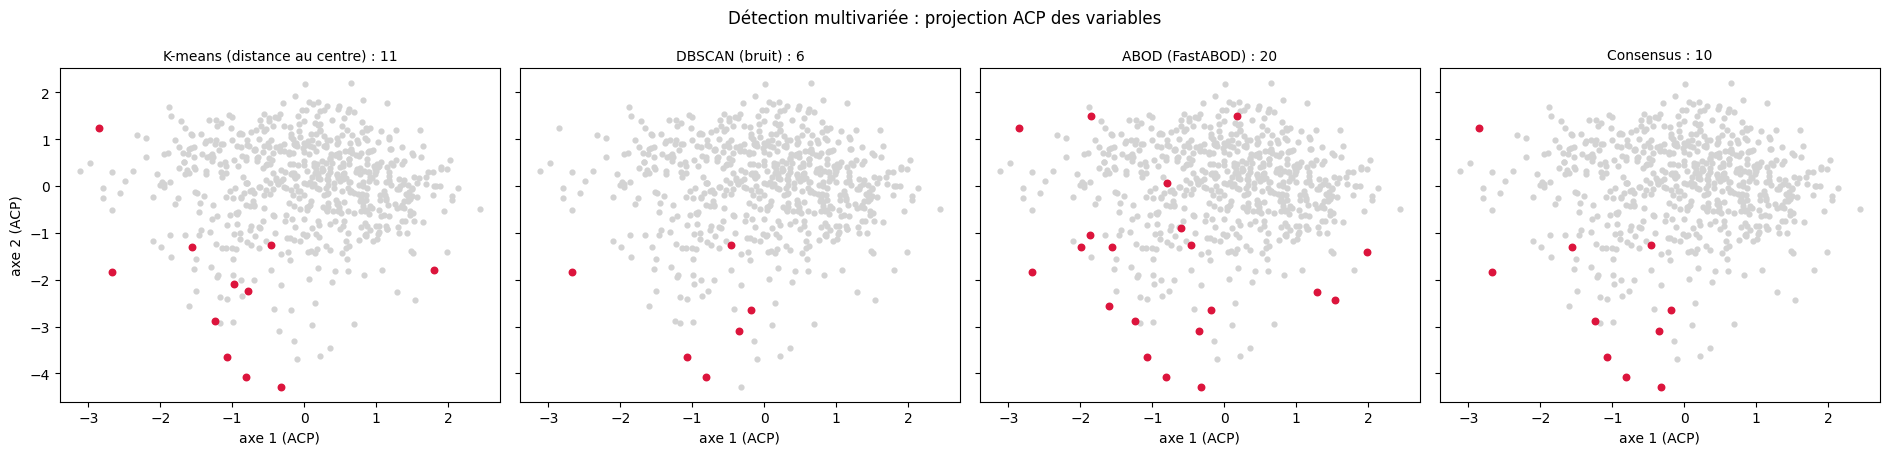


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 11, 'out_dbscan': 6, 'out_abod': 20}
Nombre de méthodes d'accord : {0: 627, 1: 13, 2: 6, 3: 4}
Lignes en consensus (>= 2 méthodes) : 10
Lignes avec au moins une valeur hors IQR : 2


In [12]:
# B) Détection par article : chaque ligne est comparée à celles du même item_code
resultat = detecter_anomalies(
    df=po, colonnes=["unit_price", "ordered_quantity", "lead_time_days"], group_by="item_code",
    show=True, contamination=0.03, min_methodes=2)

In [13]:
resultat.anomalies[cols].reset_index(drop=True)

,purchase_order_number,item_code,ordered_quantity,ordered_unit,unit_price,lead_time_days,authorization_class,order_status,n_methodes
0,PO-2024-00027,ITM-MED-002,5,case,300.27,9,ordinary,completed,3
1,PO-2018-00049,ITM-MON-002,1,kit,2474.89,14,ordinary,completed,3
2,PO-2022-00030,ITM-OFF-001,8,case,90.56,8,ordinary,completed,3
3,PO-2021-00039,ITM-OTH-001,1,unit,559.85,39,ordinary,completed,3
4,PO-2015-00008,ITM-MON-002,1,kit,2173.66,39,ordinary,completed,2
5,PO-2015-00006,ITM-CSE-001,3,unit,13839.65,7,ordinary,completed,2
6,PO-2021-00020,ITM-PRO-001,1,case,478.91,16,ordinary,completed,2
7,PO-2020-00003,ITM-MED-001,6,case,164.73,12,ordinary,completed,2
8,PO-2019-00048,ITM-MON-003,24,kit,800.19,9,expedited,completed,2
9,PO-2021-00059,ITM-MED-002,5,case,229.24,25,ordinary,completed,2


### Rapport d'analyse — anomalies

**1. Détection globale (5.1) : l'hétérogénéité des articles se fait passer pour des anomalies**
- IQR : **80 prix** atypiques (borne haute 9 767) et **33 quantités** (borne haute 73,5, borne basse négative donc inutilisable) ; **0** délai. Au total **113 lignes (17 %)** ont au moins une valeur hors IQR.
- Multivarié : K-means k = 2 (silhouette 0,45) → 17 atypiques ; DBSCAN → 6 ; ABOD → 20 (nombre fixé d'avance par `contamination`).
- Accord : aucune ligne pour 613, une méthode pour 31, deux pour 6, trois pour **0**. Les **6 lignes en consensus** sont **5 subventions** (`ITM-GRA-001`, prix de 25 727 à 28 664, quantité 1) et **1 équipement médical** (`ITM-MEQ-001`, 21 821).
- **Lecture** : ce sont les articles les plus chers, dont le prix est normal pour eux (le prix médian d'une subvention est de 25 787). Cette détection globale **ne détecte pas d'anomalies, elle retrouve la hiérarchie des prix**, exactement comme l'avait annoncé le contrôle du 1.2.

**2. Détection par article (5.2) : des résultats exploitables**
- IQR par article : **0** prix atypique, 1 quantité, 1 délai, soit **2 lignes** au lieu de 113. Dans tous les cas, le prix reste entre **0,83 et 1,19 fois la médiane de son article** (calcul complémentaire) : **il n'existe aucune anomalie de prix**.
- Multivarié : K-means k = 4 (silhouette **0,32**, faible : pas de groupes nets, mais les distances au centre restent exploitables) → 11 atypiques ; DBSCAN (ε = 0,87) → 6 points « bruit » ; ABOD → 20 (3 % de 650).
- Accord : aucune méthode 627 lignes, une 13, deux 6, trois **4** ; au total **10 lignes en consensus (1,5 %)**. Les graphiques de projection ACP les placent à la périphérie du nuage, surtout vers le bas.

**Interprétation**
- **9 lignes sur 10 ont une quantité inférieure ou égale à 20 % de la quantité habituelle de leur article** (rapport médian 0,10). Leurs prix (0,84 à 1,12 fois la médiane) et leurs délais n'ont rien d'anormal. Ce sont des **commandes de très petite taille** : commande partielle, échantillon, essai, erreur de saisie ?
- Elles sont presque toutes `ordinary` et `completed` ; une seule (`PO-2020-00003`) relève d'un des deux centres de coût rares. **Aucune ligne des 44 liées aux expéditions n'est donc signalée** (sauf cette exception) : les anomalies statistiques et le flux repéré à l'étape 4 sont **deux phénomènes distincts**.
- Les anomalies de quantité auraient été **invisibles** à l'IQR global (borne basse négative) et à l'IQR par article (1 seule détection).



---
## 6. Analyse temporelle des commandes

On étudie l'évolution des commandes et des quantités par centre de coût.
La date de commande est agrégée au mois ; les catégories de coût sont
conservées pour comparer leurs profils.

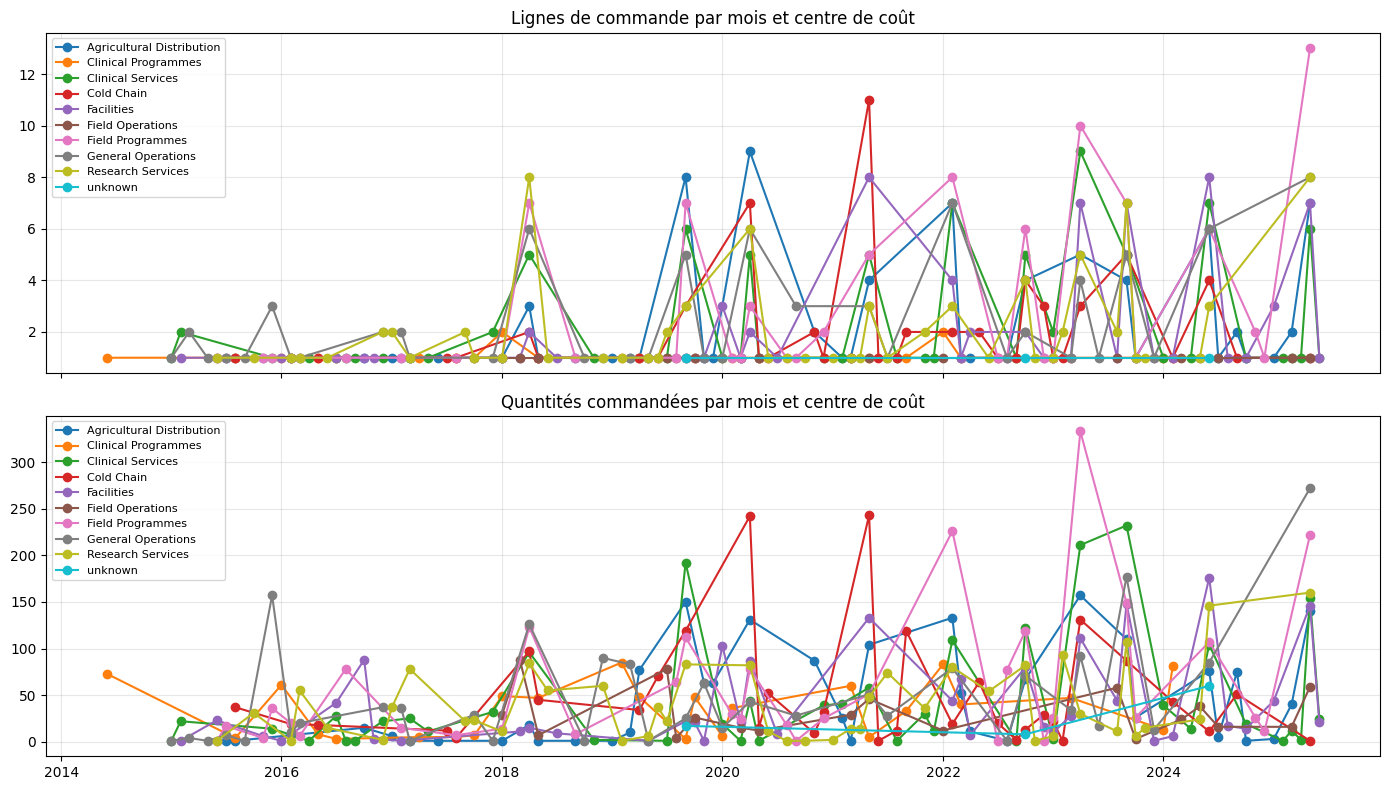

,mois,declared_cost_center,nb_lignes,quantite
0,2014-06-01,Clinical Programmes,1,73
1,2015-01-01,Clinical Services,1,1
2,2015-01-01,General Operations,1,1
3,2015-02-01,Clinical Services,2,22
4,2015-02-01,Facilities,1,1
5,2015-03-01,General Operations,2,4
6,2015-05-01,General Operations,1,1
7,2015-06-01,Facilities,1,23
8,2015-06-01,Field Programmes,1,1
9,2015-06-01,Research Services,1,1


In [14]:
po_temp = po.copy()
po_temp["order_date"] = pd.to_datetime(po_temp["order_date"], errors="coerce")
po_temp = po_temp.dropna(subset=["order_date"]).copy()
po_temp["mois"] = po_temp["order_date"].dt.to_period("M").dt.to_timestamp()
col_centre = "declared_cost_center" if "declared_cost_center" in po_temp.columns else None

if col_centre:
    po_temp[col_centre] = po_temp[col_centre].fillna("unknown").astype(str)
    agg_po = (po_temp.groupby(["mois", col_centre])
              .agg(nb_lignes=("purchase_order_number", "size"),
                   quantite=("ordered_quantity", "sum"))
              .reset_index())
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    for centre, g in agg_po.groupby(col_centre):
        axes[0].plot(g.mois, g.nb_lignes, marker="o", label=centre)
        axes[1].plot(g.mois, g.quantite, marker="o", label=centre)
    axes[0].set_title("Lignes de commande par mois et centre de coût")
    axes[1].set_title("Quantités commandées par mois et centre de coût")
    for ax in axes:
        ax.grid(alpha=.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    display(agg_po.head(15))
else:
    print("Colonne declared_cost_center absente : colonnes disponibles :", po_temp.columns.tolist())

### 6.1 Autocorrélation des quantités commandées

On agrège les quantités par mois. Les mois sans commande sont complétés
par zéro afin de conserver un calendrier régulier.

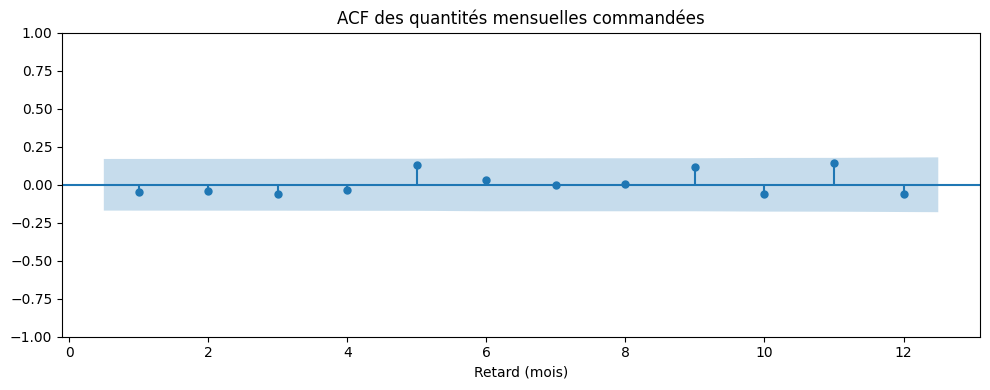

In [15]:
from statsmodels.graphics.tsaplots import plot_acf

serie_po = po_temp.groupby("mois")["ordered_quantity"].sum().sort_index()
if len(serie_po):
    serie_po = serie_po.asfreq("MS", fill_value=0)
if len(serie_po) >= 4 and serie_po.nunique() > 1:
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_acf(serie_po, lags=min(12, len(serie_po)-1), zero=False, ax=ax)
    ax.set_title("ACF des quantités mensuelles commandées")
    ax.set_xlabel("Retard (mois)")
    plt.tight_layout()
    plt.show()
else:
    print("Série trop courte ou constante pour l'ACF.")

## 7. Analyse textuelle des descriptions d'articles 

TF-IDF permet d'extraire les termes et expressions qui caractérisent
les descriptions d'articles. Les bigrammes (n-grams de taille 2)
préservent certaines expressions composées.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

textes_po = po["item_description"].fillna("").astype(str)
tfidf_po_vectorizer = TfidfVectorizer(
    lowercase=True, stop_words="english",
    ngram_range=(1, 2), min_df=2
)
try:
    X_po_tfidf = tfidf_po_vectorizer.fit_transform(textes_po)
    scores_po = np.asarray(X_po_tfidf.sum(axis=0)).ravel()
    termes_po = tfidf_po_vectorizer.get_feature_names_out()
    top_po = (pd.DataFrame({"terme": termes_po, "score_tfidf": scores_po})
              .sort_values("score_tfidf", ascending=False))
    display(top_po.head(25))
except ValueError as e:
    print("TF-IDF non calculable :", e)

,terme,score_tfidf
107,service,36.682127
10,case,32.435858
58,material,27.932866
39,general,25.962903
54,maintenance,25.655161
31,equipment,24.837568
114,supplies,23.262754
124,transport,21.479070
69,orchard,20.176886
79,produce pallet,19.947111


### 7.1 Topic modeling LDA des descriptions

LDA est appliqué à une matrice de comptage, et non à la matrice TF-IDF.
Le nombre de topics (ici 3) est un choix exploratoire à discuter.
Les mots affichés servent à interpréter les thèmes ; ils ne constituent
pas automatiquement des catégories métier.

In [17]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

cv_po = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
try:
    X_po_count = cv_po.fit_transform(textes_po)
    vocab_po = cv_po.get_feature_names_out()
    if X_po_count.shape[0] >= 10 and X_po_count.shape[1] >= 3:
        lda_po = LatentDirichletAllocation(
            n_components=min(3, X_po_count.shape[1]),
            random_state=42, max_iter=20
        )
        distrib_po = lda_po.fit_transform(X_po_count)
        for k, composante in enumerate(lda_po.components_):
            ids = composante.argsort()[-10:][::-1]
            print(f"Topic {k+1} : " + ", ".join(vocab_po[ids]))
        po_topics = po.copy()
        po_topics["topic_lda"] = distrib_po.argmax(axis=1)
        if col_centre:
            display(pd.crosstab(po_topics["topic_lda"],
                                po_topics[col_centre], normalize="index").round(2))
    else:
        print("Corpus trop petit ou vocabulaire trop réduit pour LDA.")
except ValueError as e:
    print("LDA non calculable :", e)

Topic 1 : material, supplies, material pack, pack, equipment, administration supplies, administration, sterile administration, sterile, general facility
Topic 2 : service, case, transport, kit, field, maintenance, office supply, office, supply, supply case
Topic 3 : clinical, service, general, case, general clinical, clinical consumable, consumable, consumable case, cold, storage


declared_cost_center,Agricultural Distribution,Clinical Programmes,Clinical Services,Cold Chain,Facilities,Field Operations,Field Programmes,General Operations,Research Services,unknown
topic_lda,,,,,,,,,,
0,0.13,0.04,0.13,0.12,0.10,0.02,0.18,0.11,0.15,0.01
1,0.12,0.00,0.17,0.10,0.13,0.04,0.16,0.15,0.12,0.00
2,0.15,0.10,0.12,0.10,0.14,0.02,0.10,0.13,0.14,0.00


## Synthèse — Identification de deux circuits d'approvisionnement spécialisés

L'analyse des commandes met en évidence deux groupes particulièrement intéressants : `Clinical Programmes` et `Field Operations`.

Le premier groupe comprend **26 lignes d'achat**, toutes associées au partenaire `BP-30078`. Les commandes concernent principalement des consommables médicaux et des échantillons biologiques. Elles sont associées aux sites `FCL-1010` et `FCL-1007`. Le recoupement avec les expéditions montre que chacune de ces commandes est suivie d'une expédition clinique exactement **16 jours après la date de commande**.

Le second groupe comprend **18 lignes d'achat**, également toutes associées à `BP-30078`. Il concerne des équipements de protection, de stockage au froid et de suivi environnemental. Les commandes sont réparties entre `FCL-1030`, `FCL-1019` et `FCL-1020`. Chacune est suivie d'une expédition wildlife exactement **19 jours après la commande**.

Ces deux délais constants constituent un indice fort d'une organisation logistique planifiée. Ils suggèrent que les commandes ne sont pas indépendantes des expéditions, mais qu'elles s'inscrivent dans deux circuits opérationnels distincts.

Un autre élément mérite une vérification : le partenaire `BP-30078` est identifié avec le rôle `carrier` dans les données des partenaires, alors qu'il apparaît comme fournisseur de toutes les commandes de ces deux groupes.
